In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
import cmocean

import src.plotting as plot
import src.utils as utils
from src.config import *

In [3]:
DIR_TRANSIENT = os.path.join(DIR_OUTPUT, "transient")

DIR_AMOC_ON = os.path.join(DIR_OUTPUT, "pi", "pi-amoc-on")
DIR_AMOC_ON_TRANSIENT = os.path.join(DIR_TRANSIENT, "amoc-on")

DIR_AMOC_OFF = os.path.join(DIR_OUTPUT, "pi", "pi-amoc-off")
DIR_AMOC_OFF_TRANSIENT = os.path.join(DIR_TRANSIENT, "amoc-off")

model_ice = "yelmo"

In [4]:
def load_states_atm(DIR, run, mask, var="t2a", dataset="atm.nc", months=12, n_years=1000):
    """
    Load the final states of the quasi-equilibrium runs for the atmospheric variable.
    This is from the full 3D field.

    Parameters
    ----------
    DIR : str
        The directory containing the hysteresis runs.
    months : list
        The list of months to average over (0-based indexing, e.g. [0, 1, 2] for Jan-Mar). 12 is yearly
    """

    # Check if runs is list or 1d array, if not make it a list
    # If runs is None, DIR contains full path, set runs to empty string to avoid error in os.path.join
    if run is None:
        run = ""

    fpath = os.path.join(DIR, run, dataset)
    ds = xr.open_dataset(fpath, mode='r')
    
    # Pre-select smaller area to save costs.
    try:
        ds = ds[var].sel(lat=slice(55, 86), lon=slice(-75, -5))
    except KeyError:
        print(f"Not enough timepoints for variable in {run}. Skipping...")
        return None

    # Mask to include data only above Greenland
    da_masked = ds.where(mask)

    # Calculate spatial weighted average
    weights = xr.DataArray(
        np.cos(np.deg2rad(da_masked.lat)),
        coords={"lat": da_masked.lat},
        dims=["lat"],
    )

    data = (
        da_masked
        .isel(mon=months)
        .weighted(weights)
        .mean(dim=["lat", "lon"])
        .mean("mon")
    )

    return data


def get_collapse_times(directory, runs, threshold):
    times = []

    for run in runs:
        with xr.open_dataset(
            os.path.join(directory, run, "ice_GRL-16KM_ts.nc")
        ) as ds:
            V_sle = ds.V_sle.values - eq_amoc_on_init
            crossing = np.flatnonzero(V_sle < threshold)

            times.append(
                float(ds.time.values[crossing[0]])
                if crossing.size > 0
                else np.nan
            )

    return times


In [5]:
runs_amoc_on = [
    "co2_280_620_run-1",
    "co2_280_820_run-1",
    "co2_280_1220_run-1",
]

runs_amoc_off = [
    "co2_280_780_run-1",
    "co2_280_980_run-1",
    "co2_280_1380_run-1",
]

# Tipping points for AMOC on and off (ppm)
TP_amoc_on = 420
TP_amoc_off = 580

CO2_target_amoc_on = np.array([620, 820, 1220])
CO2_target_amoc_off = np.array([780, 980, 1380])

CO2_target_rel_amoc_on = CO2_target_amoc_on - TP_amoc_on
CO2_target_rel_amoc_off = CO2_target_amoc_off - TP_amoc_off

months_summer = [5, 6, 7]
months_winter = [11, 0, 1]
months_year = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]  # For integrating e.g. yearly precipitation

In [6]:
# Load PI data
ds_GIS_pi_amoc_on_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON, 'ice_GRL-16KM_ts.nc'), mode='r')
ds_GIS_pi_amoc_off_ts = xr.open_dataset(os.path.join(DIR_AMOC_OFF, 'ice_GRL-16KM_ts.nc'), mode='r')

# Get the initial GIS state from the end of the pi-amoc-on run
eq_amoc_on_init = float(ds_GIS_pi_amoc_on_ts["V_sle"].values[-1])
# eq_amoc_off_init = float(ds_GIS_pi_amoc_off_ts["V_sle"].values[-1])

ds_atm_pi_amoc_on = xr.open_dataset(os.path.join(DIR_AMOC_ON, "atm.nc"), mode='r')
mask_grl_atm = utils.create_grl_atm_mask(ds_atm_pi_amoc_on.lon, ds_atm_pi_amoc_on.lat)

t2a_amoc_on_init = float(load_states_atm(DIR_AMOC_ON, None, mask_grl_atm, var="t2a", months=months_summer, n_years=1000).mean(dim="time")) - 273.15
t2a_amoc_off_init = float(load_states_atm(DIR_AMOC_OFF, None, mask_grl_atm, var="t2a", months=months_summer, n_years=1000).mean(dim="time")) - 273.15

prcs_amoc_on_init = float(load_states_atm(DIR_AMOC_ON, None, mask_grl_atm, var="prcs", months=months_year, n_years=1000).mean(dim="time"))
prcs_amoc_off_init = float(load_states_atm(DIR_AMOC_OFF, None, mask_grl_atm, var="prcs", months=months_year, n_years=1000).mean(dim="time"))

In [7]:
print(prcs_amoc_on_init, prcs_amoc_off_init)
print(t2a_amoc_on_init, t2a_amoc_off_init)

0.8079767020153918 0.4920736263850205
-4.9561871845979795 -7.201633886601655


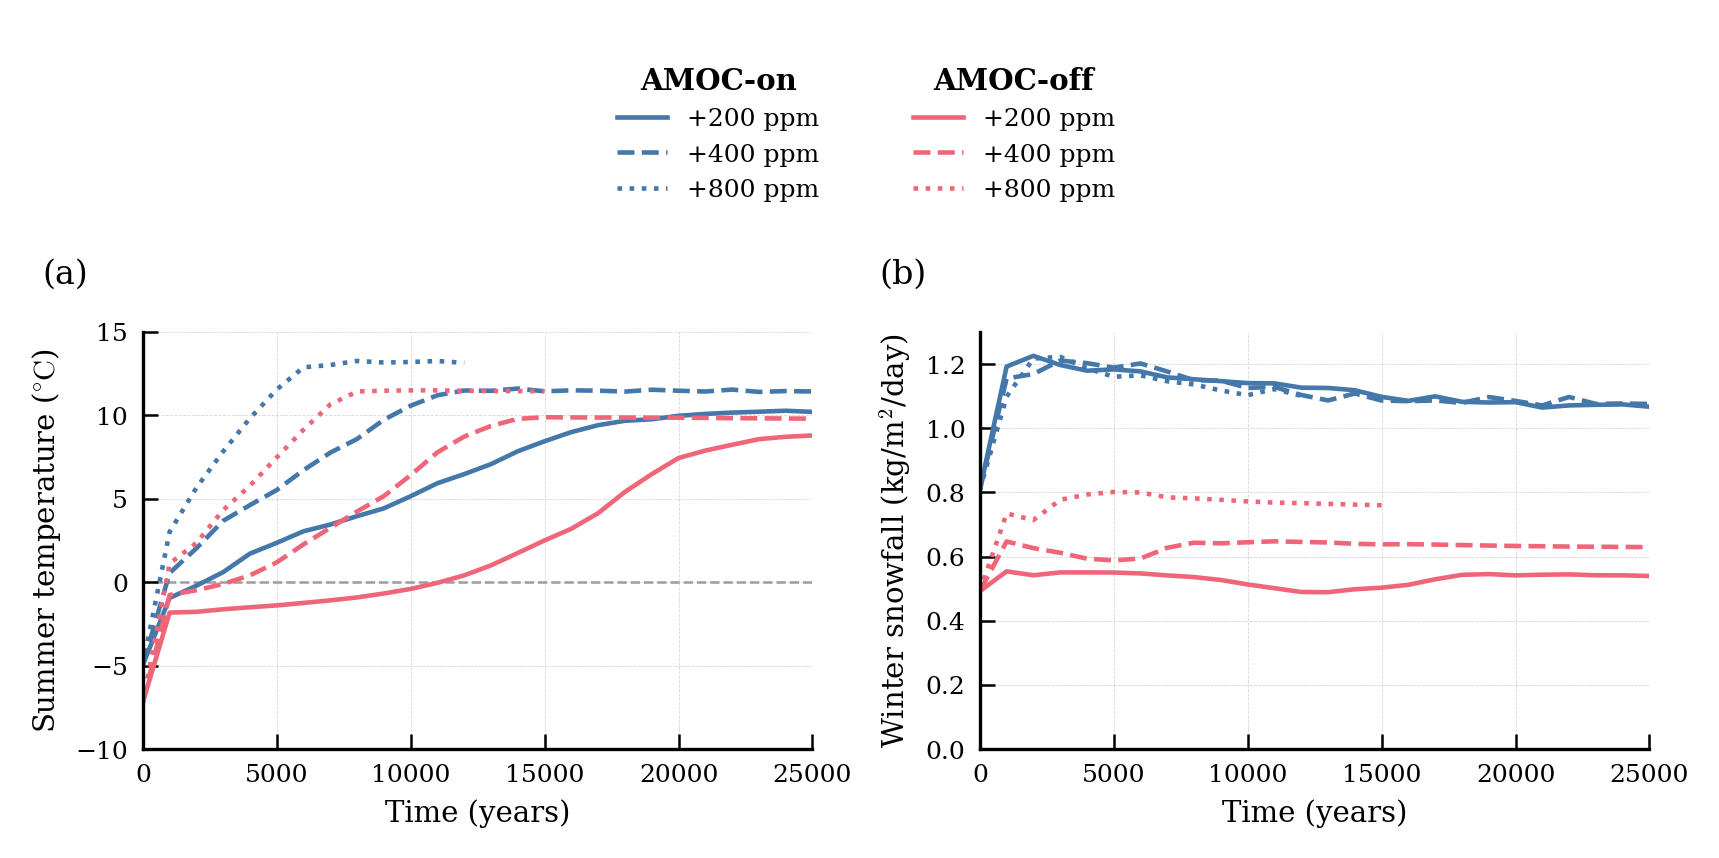

In [8]:
fig = plt.figure(
    figsize=(0.9 * plot.width_twocol, 0.7 * plot.height_twocol)
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[0.5, 1.0],
    hspace=0.3,
    wspace=0.25,
)

ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])

# One bottom panel with a secondary y-axis for percentages
ax_legend = fig.add_subplot(gs[0, :])
ax_legend.axis("off")

lw = 1.1
marker_size = 4
s_text = 2.5

# colors = [plt.cm.YlOrRd(x) for x in np.linspace(0.4, 1.0, 3)]
linestyles = ["solid", "dashed", "dotted"]

for i, (run, CO2_target_rel) in enumerate(zip(runs_amoc_on, CO2_target_rel_amoc_on)):

    color = plot.get_color(0)
    ls = linestyles[i]

    t2a_da = load_states_atm(
        DIR_AMOC_ON_TRANSIENT, run, mask_grl_atm, var="t2a", months=months_summer
    )
    prcs_da = load_states_atm(
        DIR_AMOC_ON_TRANSIENT, run, mask_grl_atm, var="prcs", months=months_winter
    )

    if t2a_da is not None:
        t2a_da = t2a_da - 273.15
        time = list(t2a_da.time.values)

        t2a_da = list(t2a_da.values)
        t2a_da.insert(0, t2a_amoc_on_init)
        time.insert(0, 0) 
        ax1.plot(time, t2a_da, color=color, lw=lw, ls=ls, label=f"+{CO2_target_rel} ppm")

    if prcs_da is not None:
        time = list(prcs_da.time.values)
        prcs_da = list(prcs_da.values)

        prcs_da.insert(0, prcs_amoc_on_init)
        time.insert(0, 0)
        ax2.plot(time, prcs_da, color=color, lw=lw, ls=ls)


for i, (run, CO2_target_rel) in enumerate(zip(runs_amoc_off, CO2_target_rel_amoc_off)):
    
    color = plot.get_color(1)
    ls = linestyles[i]

    t2a_da = load_states_atm(
        DIR_AMOC_OFF_TRANSIENT, run, mask_grl_atm, var="t2a", months=months_summer  # pyright: ignore[reportArgumentType]
    )
    prcs_da = load_states_atm(
        DIR_AMOC_OFF_TRANSIENT, run, mask_grl_atm, var="prcs", months=months_winter  # pyright: ignore[reportArgumentType]
    )

    if t2a_da is not None:
        t2a_da = t2a_da - 273.15
        time = list(t2a_da.time.values)

        t2a_da = list(t2a_da.values)
        t2a_da.insert(0, t2a_amoc_off_init)
        time.insert(0, 0) 
        ax1.plot(time, t2a_da, color=color, ls=ls, lw=lw, label=f"+{CO2_target_rel} ppm")

    if prcs_da is not None:
        time = list(prcs_da.time.values)
        prcs_da = list(prcs_da.values)

        prcs_da.insert(0, prcs_amoc_off_init)
        time.insert(0, 0)
        ax2.plot(time, prcs_da, color=color, ls=ls, lw=lw)
    

for ax in (ax1, ax2):
    ax.set_xlim(0, 25000)
    ax.grid(alpha=0.5)

# Disable x-axis labels for the top row of subplots
# ax1.set_xticklabels([])

ax1.set_xlabel("Time (years)")
ax2.set_xlabel("Time (years)")

ax1.set_ylim(-10, 15)
ax2.set_ylim(0, 1.3)

ax1.set_ylabel(r"Summer temperature ($\!^\circ\!\mathrm{C}$)")
ax2.set_ylabel("Winter snowfall (kg/m$^2$/day)")

ax1.hlines(0, -100, 26000, colors='grey', linestyles='dashed', linewidth=0.8, alpha=0.8, zorder=0, lw=0.6)

# Legend in dedicated top row, 3 columns
# handles, labels = ax1.get_legend_handles_labels()
# ax_leg.axis("off")
# ax_leg.legend(handles, labels, loc="center", ncol=2, frameon=False, fontsize=6)

handles, labels = ax1.get_legend_handles_labels()
ax_legend.axis("off")

legend_on = ax_legend.legend(
    handles[:3],
    labels[:3],
    title="AMOC-on",
    loc="center left",
    bbox_to_anchor=(0.3, 0.5),
    frameon=False,
    title_fontproperties={"size": 7, "weight": "bold"}
)

ax_legend.add_artist(legend_on)
ax_legend.legend(
    handles[3:],
    labels[3:],
    title="AMOC-off",
    loc="center right",
    bbox_to_anchor=(0.66, 0.5),
    frameon=False,
    title_fontproperties={"size": 7, "weight": "bold"}
)

# Add figure labels to the subplots
ax1.text(-0.15, 1.1, "(a)", transform=ax1.transAxes, va='bottom', ha='left')
ax2.text(-0.15, 1.1, "(b)", transform=ax2.transAxes, va='bottom', ha='left')

plt.savefig(os.path.join(DIR_FIG, "GrIS_transients_temp_snow.pdf"), format="pdf", bbox_inches="tight")


In [9]:
collapse_thresholds = np.arange(-7.0, -7.5, -0.1)
results = []

for threshold in collapse_thresholds:
    times_on = get_collapse_times(
        DIR_AMOC_ON_TRANSIENT, runs_amoc_on, threshold
    )
    times_off = get_collapse_times(
        DIR_AMOC_OFF_TRANSIENT, runs_amoc_off, threshold
    )

    for co2_rel, time_on, time_off in zip(
        CO2_target_rel_amoc_on, times_on, times_off
    ):
        difference = time_off - time_on
        percentage = 100 * difference / time_on

        results.append(
            {
                "Threshold": threshold,
                "Rel_CO2": co2_rel,
                "AMOC-on": time_on,
                "AMOC-off": time_off,
                "Diff": difference,
                "Diff_percentage": percentage,
            }
        )

AMOC-on - V_sle[-1] = -7.49373722076416 for run co2_280_620_run-1
AMOC-on - V_sle[-1] = -7.516035556793213 for run co2_280_820_run-1
AMOC-on - V_sle[-1] = -7.526978969573975 for run co2_280_1220_run-1
AMOC-off - V_sle[-1] = -7.4439215660095215 for run co2_280_780_run-1
AMOC-off - V_sle[-1] = -7.4940714836120605 for run co2_280_980_run-1
AMOC-off - V_sle[-1] = -7.517650604248047 for run co2_280_1380_run-1


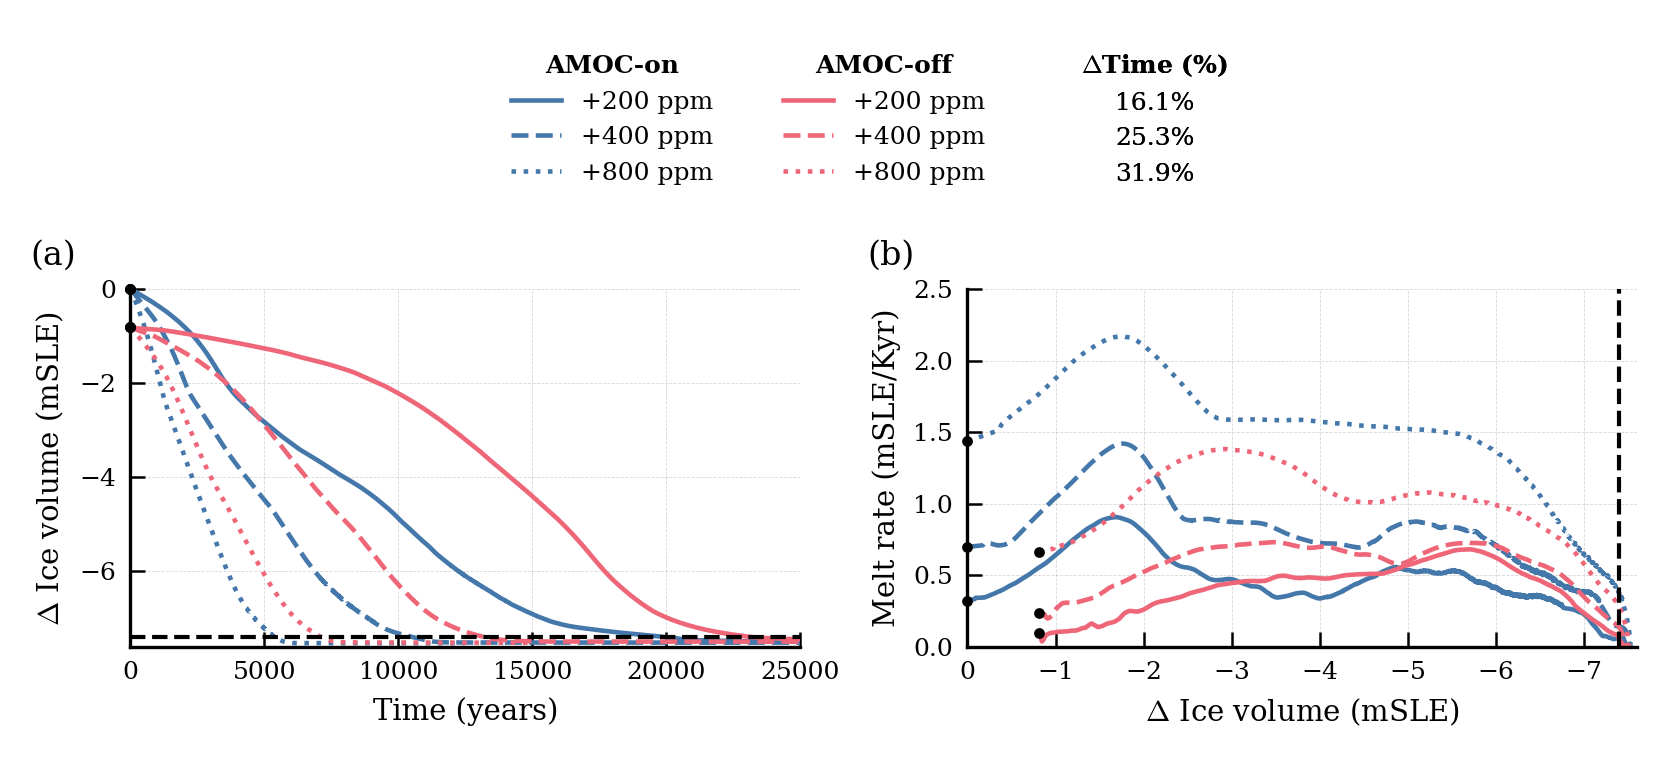

In [10]:
fig = plt.figure(
    figsize=(0.9 * plot.width_twocol, 0.6 * plot.height_twocol)
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[0.5, 1.0],
    hspace=0.3,
    wspace=0.25,
)

ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])

# One bottom panel with a secondary y-axis for percentages
ax_legend = fig.add_subplot(gs[0, :])
ax_legend.axis("off")

lw = 1.1
marker_size = 4
s_text = 2.5

window = 500

threshold_for_legend = -7.4


# colors = [plt.cm.YlOrRd(x) for x in np.linspace(0.4, 1.0, 3)]
linestyles = ["solid", "dashed", "dotted"]
for i, (run, CO2_target_rel) in enumerate(zip(runs_amoc_on, CO2_target_rel_amoc_on)):
    ds = xr.open_dataset(os.path.join(DIR_AMOC_ON_TRANSIENT, run, "ice_GRL-16KM_ts.nc"))
    V_sle = ds.V_sle.values - eq_amoc_on_init

    color = plot.get_color(0)
    ls = linestyles[i]

    ax1.plot(ds.time, V_sle, label=f"+{CO2_target_rel} ppm", color=color, lw=lw, ls=ls)

    V_sle_smooth = np.convolve(
        V_sle,
        np.ones(window) / window,
        mode="valid",
    )

    time_smooth = ds.time.values[
        window // 2 : window // 2 + len(V_sle_smooth)
    ]
    # melt_rate = -np.gradient(V_sle_smooth, time_smooth) * 1000

    # Make sure lines start at the initial V_sle value
    V_sle_smooth = np.insert(V_sle_smooth, 0, V_sle[0])
    time_smooth = np.insert(time_smooth, 0, ds.time.values[0])
    melt_rate = -np.gradient(V_sle_smooth, time_smooth) * 1000

    ax2.plot(
        V_sle_smooth,
        melt_rate,
        color=color,
        lw=lw,
        ls=ls,
    )

    ax2.scatter(V_sle[0], melt_rate[0], color='black', s=s_text, zorder=10, clip_on=False)
    ax1.scatter(ds.time.values[0], V_sle[0], color='black', s=s_text, zorder=10, clip_on=False)
    print(f"AMOC-on - V_sle[-1] = {V_sle[-1]} for run {run}")

   
for i, (run, CO2_target_rel) in enumerate(zip(runs_amoc_off, CO2_target_rel_amoc_off)):
    ds = xr.open_dataset(os.path.join(DIR_AMOC_OFF_TRANSIENT, run, "ice_GRL-16KM_ts.nc"))
    V_sle = ds.V_sle.values - eq_amoc_on_init

    print(f"AMOC-off - V_sle[-1] = {V_sle[-1]} for run {run}")

    color = plot.get_color(1)
    ls = linestyles[i]

    ax1.plot(ds.time, V_sle, label=f"+{CO2_target_rel} ppm", color=color, ls=ls, lw=lw)

    V_sle_smooth = np.convolve(
        V_sle,
        np.ones(window) / window,
        mode="valid",
    )

    time_smooth = ds.time.values[
        window // 2 : window // 2 + len(V_sle_smooth)
    ]

    # Make sure lines start at the initial V_sle value
    V_sle_smooth = np.insert(V_sle_smooth, 0, V_sle[0])
    time_smooth = np.insert(time_smooth, 0, ds.time.values[0])
    melt_rate = -np.gradient(V_sle_smooth, time_smooth) * 1000

    ax2.plot(
        V_sle_smooth,
        melt_rate,
        color=color,
        lw=lw,
        ls=ls,
    )

    ax2.scatter(V_sle[0], melt_rate[0], color='black', s=s_text, zorder=10, clip_on=False)
    ax1.scatter(ds.time.values[0], V_sle[0], color='black', s=s_text, zorder=10, clip_on=False)



# ax3.legend(title="Volume threshold (mSLE)", ncols=2, frameon=False, title_fontproperties={"size": 6, "weight": "bold"})

ax1.set_xlim(0, 25000)
ax2.set_ylim(0, 2.5)
ax1.set_ylim(-7.6, 0)
ax2.set_xlim(0, -7.6)

ax1.hlines(y=threshold_for_legend, xmin=0, xmax=25000, color='black', linestyles='--', lw=1)
ax2.vlines(x=threshold_for_legend, ymin=0, ymax=2.5, color='black', linestyles='--', lw=1)


ax1.set_xlabel("Time (years)")
ax2.set_xlabel(r"$\Delta$ Ice volume (mSLE)")

ax1.set_ylabel(r"$\Delta$ Ice volume (mSLE)")
ax2.set_ylabel("Melt rate (mSLE/Kyr)")

for ax in [ax1, ax2]:
    ax.grid(alpha=0.5)

# Legend in dedicated top row, 3 columns
# handles, labels = ax1.get_legend_handles_labels()
# ax_leg.axis("off")
# ax_leg.legend(handles, labels, loc="center", ncol=2, frameon=False, fontsize=6)

handles, labels = ax1.get_legend_handles_labels()

percent_differences = [
    item["Diff_percentage"]
    for item in results
    if np.isclose(item["Threshold"], threshold_for_legend)
]

labels_on = labels[:3]
labels_off = labels[3:]

legend_on = ax_legend.legend(
    handles[:3],
    labels_on,
    title="AMOC-on",
    loc="center",
    bbox_to_anchor=(0.32, 0.5),
    frameon=False,
    title_fontproperties={"size": 6, "weight": "bold"},
)

ax_legend.add_artist(legend_on)

legend_off = ax_legend.legend(
    handles[3:],
    labels_off,
    title="AMOC-off",
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    frameon=False,
    title_fontproperties={"size": 6, "weight": "bold"},
)

ax_legend.add_artist(legend_off)

from matplotlib.lines import Line2D
diff_handles = [
    Line2D([], [], color="none") for _ in percent_differences
]
diff_labels = [f"{difference:.1f}%" for difference in percent_differences]

legend_diff = ax_legend.legend(
    diff_handles,
    diff_labels,
    title=r"$\boldsymbol{\Delta}$Time (%)",
    loc="center",
    bbox_to_anchor=(0.68, 0.5),
    frameon=False,
    handlelength=0,
    handletextpad=0,
    title_fontproperties={"size": 6, "weight": "bold"},
)

ax_legend.add_artist(legend_diff)

# Add figure labels to the subplots
ax1.text(-0.15, 1.05, "(a)", transform=ax1.transAxes,  va='bottom', ha='left')
ax2.text(-0.15, 1.05, "(b)", transform=ax2.transAxes,  va='bottom', ha='left')

plt.savefig(os.path.join(DIR_FIG, "GrIS_transients.pdf"), format="pdf", bbox_inches="tight")


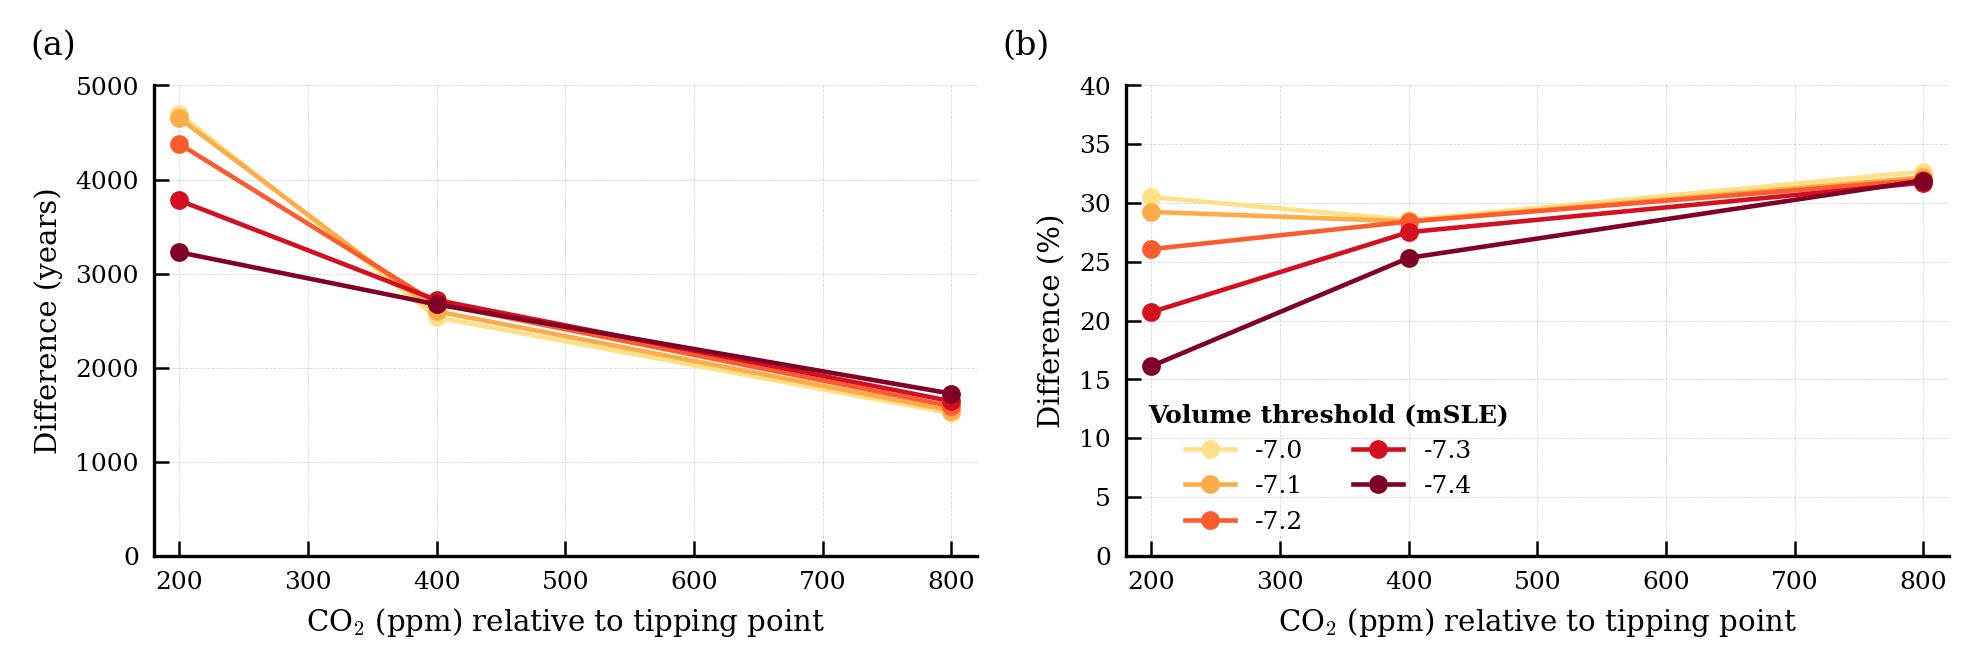

In [11]:

        

fig, ((ax1, ax2)) = plot.subplots(nrows=1, ncols=2, figsize=(0.9*plot.width_twocol, plot.height_onecol))

lw = 1.1
marker_size = 4
s_text = 2.5

window = 500


# colors = [plt.cm.YlOrRd(x) for x in np.linspace(0.4, 1.0, 3)]
linestyles = ["solid", "dashed", "dotted"]
colors_diff = [plt.cm.YlOrRd(x) for x in np.linspace(0.2, 1.0, len(collapse_thresholds))]

# Plot absolute and percentage differences in collapse timing
for i, threshold in enumerate(collapse_thresholds):
    subset = [r for r in results if r["Threshold"] == threshold]

    co2 = [row["Rel_CO2"] for row in subset]
    difference_years = [row["Diff"] for row in subset]
    difference_percent = [row["Diff_percentage"] for row in subset]

    ax1.plot(
        co2,
        difference_years,
        marker="o",
        ms=marker_size,
        lw=lw,
        color=colors_diff[i],
        label=f"{threshold:.1f}",
    )
    ax2.plot(
        co2,
        difference_percent,
        marker="o",
        ms=marker_size,
        lw=lw,
        color=colors_diff[i],
        label=f"{threshold:.1f}",
    )

ax1.set_xlabel("CO$_2$ (ppm) relative to tipping point")
ax2.set_xlabel("CO$_2$ (ppm) relative to tipping point")
ax1.set_ylabel("Difference (years)")
ax2.set_ylabel("Difference (%)")

ax2.legend(title="Volume threshold (mSLE)", ncols=2, frameon=False, title_fontproperties={"size": 6, "weight": "bold"})

ax1.set_xlim(180, 820)
ax2.set_xlim(180, 820)
ax1.set_ylim(0, 5000)
ax2.set_ylim(0, 40)

for ax in [ax1, ax2]:
    ax.grid(alpha=0.5)

# Add figure labels to the subplots
ax1.text(-0.15, 1.05, "(a)", transform=ax1.transAxes,  va='bottom', ha='left')
ax2.text(-0.15, 1.05, "(b)", transform=ax2.transAxes,  va='bottom', ha='left')

plt.savefig(os.path.join(DIR_FIG, "GrIS_transients_thresholds.pdf"), format="pdf", bbox_inches="tight")


In [12]:
import pandas as pd

results_df = pd.DataFrame(results)

display(
    results_df.style.format(
        {
            "Threshold": "{:.1f}",
            "AMOC-on": "{:,.0f}",
            "AMOC-off": "{:,.0f}",
            "Diff": "{:.0f}",
            "Diff_percentage": "{:.2f}%",
        }
    )
)

,Threshold,Rel_CO2,AMOC-on,AMOC-off,Diff,Diff_percentage
0,-7.0,200,"15,388","20,084",4696,30.52%
1,-7.0,400,"8,880","11,416",2536,28.56%
2,-7.0,800,"4,639","6,155",1516,32.68%
3,-7.1,200,"15,909","20,562",4653,29.25%
4,-7.1,400,"9,138","11,737",2599,28.44%
5,-7.1,800,"4,800","6,345",1545,32.19%
6,-7.2,200,"16,788","21,167",4379,26.08%
7,-7.2,400,"9,434","12,116",2682,28.43%
8,-7.2,800,"4,976","6,567",1591,31.97%
9,-7.3,200,"18,229","22,007",3778,20.73%


In [13]:
def load_and_plot_ice_thickness_titletime(DIR, time_ind, ax, proj=None):
    """
    Load the ice thickness dataset and delegate plotting to plot.plot_GIS_contourf_yelmo.

    Parameters
    ----------
    DIR : str
        Directory containing the experiment output.
    time_ind : int
        Time index to plot.
    ax : matplotlib.axes.Axes
        Axis to plot on.
    proj : cartopy.crs projection
        Kept for backward compatibility with existing calls.
    title : str
        Title for the subplot.

    Returns
    -------
    cf : matplotlib.contour.QuadContourSet
        Contourf object for shared colorbar creation.
    """

    fpath_GIS = os.path.join(DIR, "ice_GRL-16KM.nc")
    ds_GIS = xr.open_dataset(fpath_GIS, mode="r")

    mask = ds_GIS["mask_bed"].isel(time=time_ind) > 0

    title = f"{int(ds_GIS['time'].isel(time=time_ind).values)} years"

    fig, ax, cf = plot.plot_GIS_contourf_yelmo(
        ds_GIS,
        "H_ice",
        time_index=time_ind,
        mask=mask,
        ax=ax,
        levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5]
    )
    ax.set_title(title, fontsize=5)

    return cf

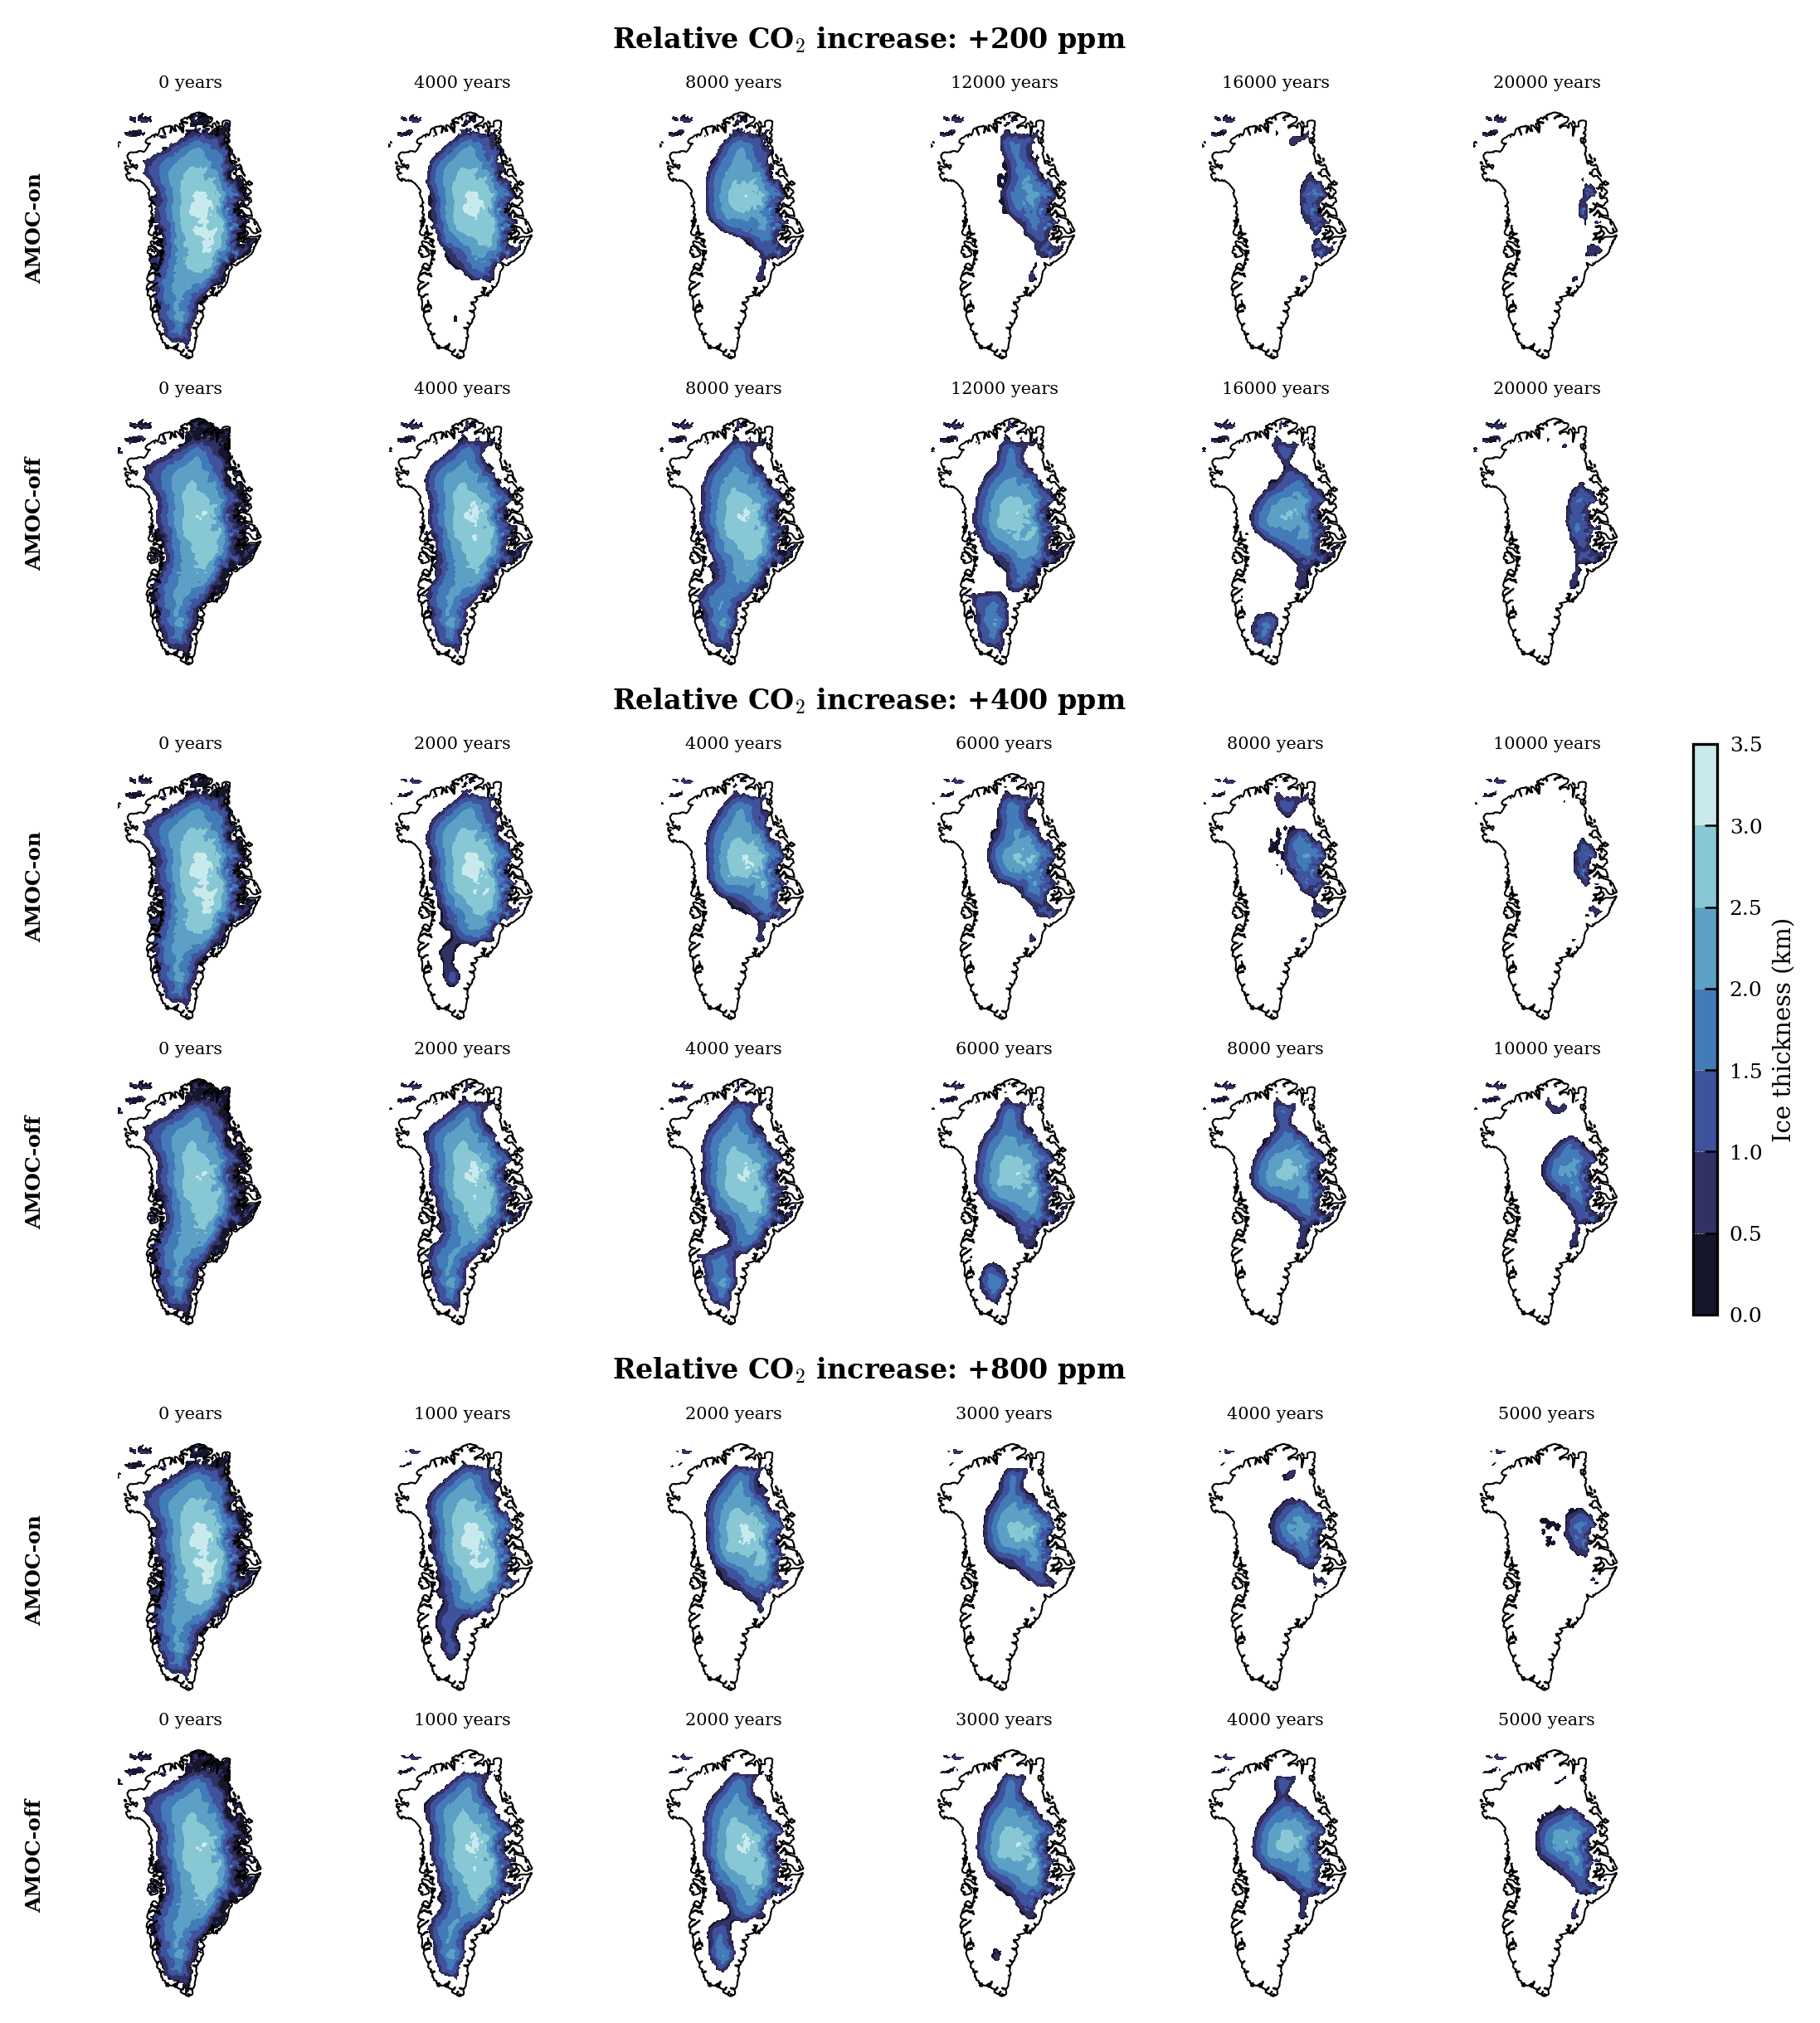

In [ ]:
fig = plt.figure(figsize=(plot.width_twocol, 1.8*plot.height_twocol), constrained_layout=True)
proj = ccrs.Stereographic(central_longitude=-45, central_latitude=90, true_scale_latitude=70)

# Outer grid: 2 rows (top, bottom) + 1 narrow cbar column on the right, 1 narrow col on the left
outer = gridspec.GridSpec(
    6, 3,
    width_ratios= [0.005, 1, 0.015],
    height_ratios=[0.05, 1, 0.05, 1, 0.05, 1],
    figure=fig,
)

# TOP row: 2 columns inside left area
gs_top_title = gridspec.GridSpecFromSubplotSpec(
    1, 1,
    subplot_spec=outer[0, 1],
)

gs_top = gridspec.GridSpecFromSubplotSpec(
    2, 6,
    subplot_spec=outer[1, 1],
)

gs_middle_title = gridspec.GridSpecFromSubplotSpec(
    1, 1,
    subplot_spec=outer[2, 1],
)

gs_middle = gridspec.GridSpecFromSubplotSpec(
    2, 6,
    subplot_spec=outer[3, 1],
)

gs_bottom_title = gridspec.GridSpecFromSubplotSpec(
    1, 1,
    subplot_spec=outer[4, 1],
)

gs_bottom = gridspec.GridSpecFromSubplotSpec(
    2, 6,
    subplot_spec=outer[5, 1],
)


# Colorbar area
ax_cb = fig.add_subplot(outer[3, 2])
ax_cb_dummy_1 = fig.add_subplot(outer[0:3, 2])   # dummy subplot for alignment
ax_cb_dummy_2 = fig.add_subplot(outer[4:6, 2])   # dummy subplot for alignment
ax_cb_dummy_1.axis('off')
ax_cb_dummy_2.axis('off')

# AMOC state area
ax_amoc_state_1 = fig.add_subplot(outer[1, 0])
ax_amoc_state_2 = fig.add_subplot(outer[3, 0])
ax_amoc_state_3 = fig.add_subplot(outer[5, 0])

# Titles
ax_top_title = fig.add_subplot(gs_top_title[0, 0])
ax_middle_title = fig.add_subplot(gs_middle_title[0, 0])
ax_bottom_title = fig.add_subplot(gs_bottom_title[0, 0])
ax_top_title.axis('off')
ax_middle_title.axis('off')
ax_bottom_title.axis('off')

ax_top_title.text(0.5, 0.4, "Relative CO$_2$ increase: +200 ppm", ha="center", va="center", fontweight="bold")
ax_middle_title.text(0.5, 0.4, "Relative CO$_2$ increase: +400 ppm", ha="center", va="center", fontweight="bold")
ax_bottom_title.text(0.5, 0.4, "Relative CO$_2$ increase: +800 ppm", ha="center", va="center", fontweight="bold")

# ---- Top row (projection axes) ----
axtop_1 = fig.add_subplot(gs_top[0, 0], projection=proj)
axtop_2 = fig.add_subplot(gs_top[0, 1], projection=proj)
axtop_3 = fig.add_subplot(gs_top[0, 2], projection=proj)
axtop_4 = fig.add_subplot(gs_top[0, 3], projection=proj)
axtop_5 = fig.add_subplot(gs_top[0, 4], projection=proj)
axtop_6 = fig.add_subplot(gs_top[0, 5], projection=proj)

axtop_7 = fig.add_subplot(gs_top[1, 0], projection=proj)
axtop_8 = fig.add_subplot(gs_top[1, 1], projection=proj)
axtop_9 = fig.add_subplot(gs_top[1, 2], projection=proj)
axtop_10 = fig.add_subplot(gs_top[1, 3], projection=proj)
axtop_11 = fig.add_subplot(gs_top[1, 4], projection=proj)
axtop_12 = fig.add_subplot(gs_top[1, 5], projection=proj)

# ---- Middle row (projection axes) ----
axmiddle_1 = fig.add_subplot(gs_middle[0, 0], projection=proj)
axmiddle_2 = fig.add_subplot(gs_middle[0, 1], projection=proj)
axmiddle_3 = fig.add_subplot(gs_middle[0, 2], projection=proj)
axmiddle_4 = fig.add_subplot(gs_middle[0, 3], projection=proj)
axmiddle_5 = fig.add_subplot(gs_middle[0, 4], projection=proj)
axmiddle_6 = fig.add_subplot(gs_middle[0, 5], projection=proj)

axmiddle_7 = fig.add_subplot(gs_middle[1, 0], projection=proj)
axmiddle_8 = fig.add_subplot(gs_middle[1, 1], projection=proj)
axmiddle_9 = fig.add_subplot(gs_middle[1, 2], projection=proj)
axmiddle_10 = fig.add_subplot(gs_middle[1, 3], projection=proj)
axmiddle_11 = fig.add_subplot(gs_middle[1, 4], projection=proj)
axmiddle_12 = fig.add_subplot(gs_middle[1, 5], projection=proj)

# ---- Bottom row (projection axes) ----
axbottom_1 = fig.add_subplot(gs_bottom[0, 0], projection=proj)
axbottom_2 = fig.add_subplot(gs_bottom[0, 1], projection=proj)
axbottom_3 = fig.add_subplot(gs_bottom[0, 2], projection=proj)
axbottom_4 = fig.add_subplot(gs_bottom[0, 3], projection=proj)
axbottom_5 = fig.add_subplot(gs_bottom[0, 4], projection=proj)
axbottom_6 = fig.add_subplot(gs_bottom[0, 5], projection=proj)

axbottom_7 = fig.add_subplot(gs_bottom[1, 0], projection=proj)
axbottom_8 = fig.add_subplot(gs_bottom[1, 1], projection=proj)
axbottom_9 = fig.add_subplot(gs_bottom[1, 2], projection=proj)
axbottom_10 = fig.add_subplot(gs_bottom[1, 3], projection=proj)
axbottom_11 = fig.add_subplot(gs_bottom[1, 4], projection=proj)
axbottom_12 = fig.add_subplot(gs_bottom[1, 5], projection=proj)


fname_amoc_on = "co2_280_620_run-1"
fname_amoc_off = "co2_280_780_run-1"
cf1 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 0, axtop_1, proj)
cf2 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 4, axtop_2, proj)
cf3 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 8, axtop_3, proj)
cf4 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 12, axtop_4, proj)
cf5 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 16, axtop_5, proj)
cf6 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 20, axtop_6, proj)

cf7 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 0, axtop_7, proj)
cf8 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 4, axtop_8, proj)
cf9 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 8, axtop_9, proj)
cf10 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 12, axtop_10, proj)
cf11 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 16, axtop_11, proj)
cf12 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 20, axtop_12, proj)


fname_amoc_on = "co2_280_820_run-1"
fname_amoc_off = "co2_280_980_run-1"
cf1 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 0, axmiddle_1, proj)
cf2 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 2, axmiddle_2, proj)
cf3 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 4, axmiddle_3, proj)
cf4 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 6, axmiddle_4, proj)
cf5 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 8, axmiddle_5, proj)
cf6 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 10, axmiddle_6, proj)

cf7 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 0, axmiddle_7, proj)
cf8 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 2, axmiddle_8, proj)
cf9 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 4, axmiddle_9, proj)
cf10 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 6, axmiddle_10, proj)
cf11 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 8, axmiddle_11, proj)
cf12 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 10, axmiddle_12, proj)


fname_amoc_on = "co2_280_1220_run-1"
fname_amoc_off = "co2_280_1380_run-1"
cf1 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 0, axbottom_1, proj)
cf2 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 1, axbottom_2, proj)
cf3 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 2, axbottom_3, proj)
cf4 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 3, axbottom_4, proj)
cf5 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 4, axbottom_5, proj)
cf6 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_ON_TRANSIENT, fname_amoc_on), 5, axbottom_6, proj)

cf7 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 0, axbottom_7, proj)
cf8 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 1, axbottom_8, proj)
cf9 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 2, axbottom_9, proj)
cf10 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 3, axbottom_10, proj)
cf11 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 4, axbottom_11, proj)
cf12 = load_and_plot_ice_thickness_titletime(os.path.join(DIR_AMOC_OFF_TRANSIENT, fname_amoc_off), 5, axbottom_12, proj)

# Create colorbar for the ice thickness plots based on cf1 (they all use the same levels)
cbar = fig.colorbar(
    cf1,
    cax=ax_cb,
    orientation='vertical',
    label='Ice thickness (km)',
    extend="both",
)

for ax_amoc_state in [ax_amoc_state_1, ax_amoc_state_2, ax_amoc_state_3]:
    # Disable axis ax_amoc_state
    ax_amoc_state.axis('off')
    ax_amoc_state.text(
        0.5, 0.75, "AMOC-on",
        transform=ax_amoc_state.transAxes,
        fontweight='bold',
        fontsize=6,
        va='center', ha='center', rotation='vertical'
    )
    ax_amoc_state.text(
        0.5, 0.25, "AMOC-off",
        transform=ax_amoc_state.transAxes,
        fontweight='bold',
        fontsize=6,
        va='center', ha='center', rotation='vertical'
    )

plt.savefig(os.path.join(DIR_FIG, "GrIS_transients_spatial.pdf"), format="pdf", bbox_inches="tight")


### Animations of ice sheet evolution

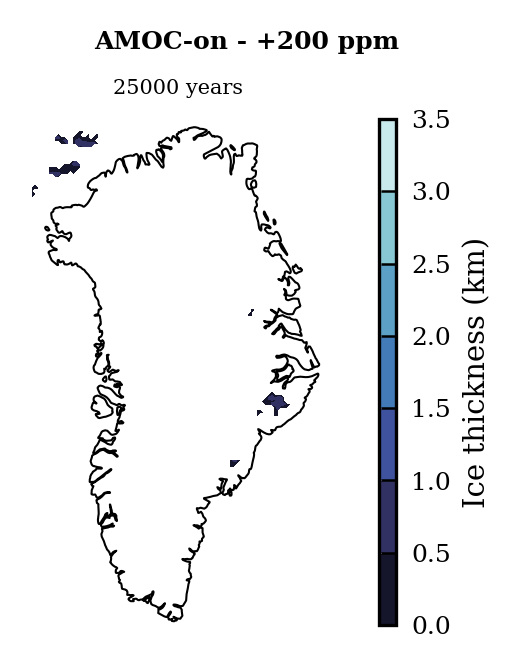

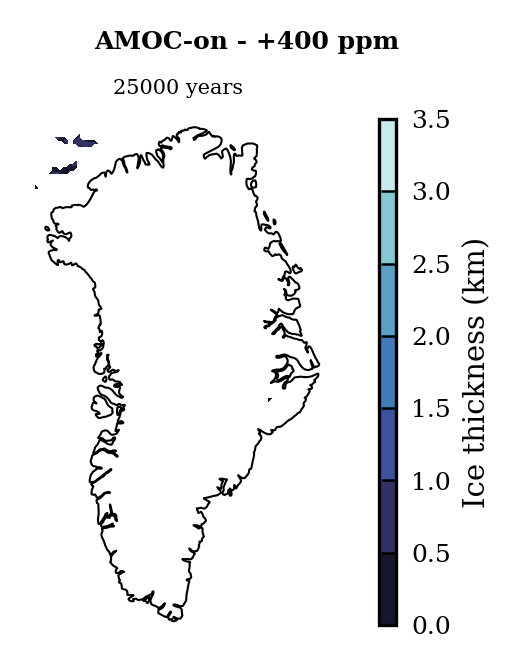

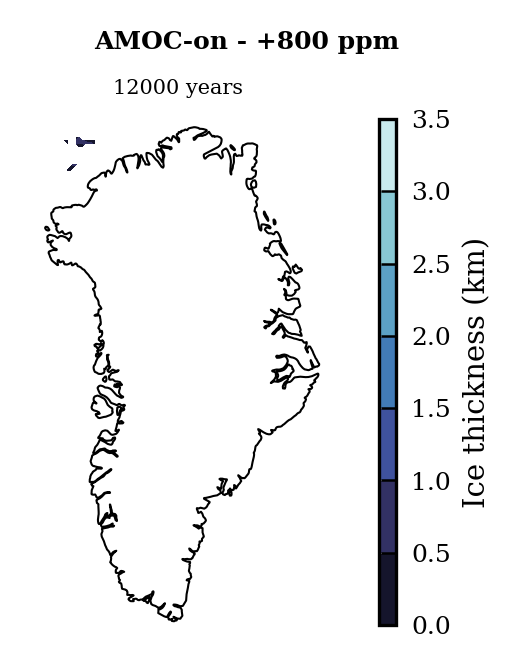

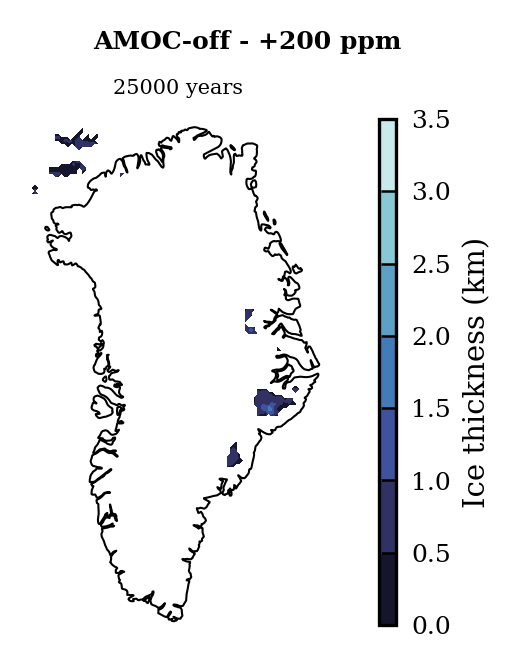

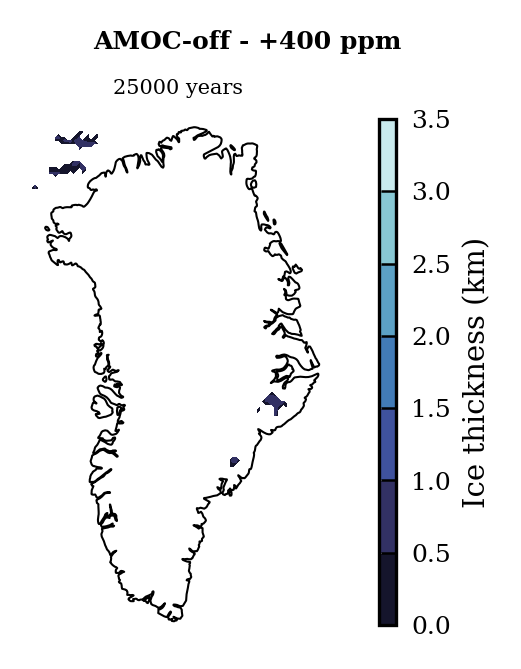

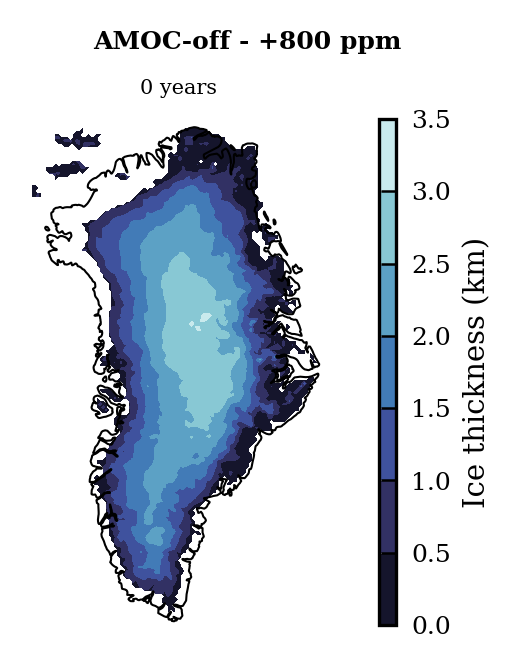

In [15]:
from matplotlib.animation import FuncAnimation

fnames = [
    "co2_280_620_run-1", "co2_280_820_run-1", "co2_280_1220_run-1",
    "co2_280_780_run-1", "co2_280_980_run-1", "co2_280_1380_run-1",
]
titles = [
    "AMOC-on - +200 ppm", "AMOC-on - +400 ppm", "AMOC-on - +800 ppm",
    "AMOC-off - +200 ppm", "AMOC-off - +400 ppm", "AMOC-off - +800 ppm",
]
fnames_out = [title.split(" ")[0] + "_" + fname for fname, title in zip(fnames, titles)]

def plot_anim_frame(ds_GIS, time_ind, ax):
    mask = ds_GIS["mask_bed"].isel(time=time_ind) > 0

    title = f"{int(ds_GIS['time'].isel(time=time_ind).values)} years"

    fig, ax, cf = plot.plot_GIS_contourf_yelmo(
        ds_GIS,
        "H_ice",
        time_index=time_ind,
        mask=mask,
        ax=ax,
        levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5]
    )
    ax.set_title(title, fontsize=5)

    return cf

for fname, title, fname_out in zip(fnames, titles, fnames_out):

    ## Set up figure 
    fig = plt.figure(figsize=(0.5*plot.width_onecol, plot.height_onecol), constrained_layout=True)
    proj = ccrs.Stereographic(central_longitude=-45, central_latitude=90, true_scale_latitude=70)

    # Outer grid: 2 rows (top, bottom) + 1 narrow cbar column on the right, 1 narrow col on the left
    outer = gridspec.GridSpec(
        1, 2,
        width_ratios= [1, 0.05], 
        figure=fig
    )
    # Colorbar area
    ax_cb = fig.add_subplot(outer[0, 1])   # only second row

    ax1 = fig.add_subplot(outer[0, 0], projection=proj)

    if "AMOC-on" in title:
        fpath = os.path.join(DIR_AMOC_ON_TRANSIENT, fname, "ice_GRL-16KM.nc")
    else:
        fpath = os.path.join(DIR_AMOC_OFF_TRANSIENT, fname, "ice_GRL-16KM.nc")
    ds = xr.open_dataset(fpath, engine="netcdf4", mode="r")

    time_inds = [i for i in range(len(ds.time))]

    # Add title above the animation
    fig.suptitle(title, fontweight="bold", fontsize=6)
    
    # Plot the first frame to create the colorbar mappable.
    cf1 = plot_anim_frame(ds, time_inds[0], ax1)

    # Create colorbar for the ice thickness plots based on cf1 (they all use the same levels)
    cbar = fig.colorbar(
        cf1,
        cax=ax_cb,
        orientation='vertical',
        label='Ice thickness (km)',
        extend="both",
    )

    def update(time_ind):
        ax1.clear()
        return (plot_anim_frame(ds, time_ind, ax1),)

    anim = FuncAnimation(
        fig,
        update,
        frames=time_inds,
        interval=500,
        blit=False,
        repeat=True,
    )

    anim.save(
        os.path.join(DIR_FIG, f"{fname_out}_ice_thickness.gif"),
        writer="pillow",
        fps=3,
    )

